# Loan Approval Prediction Using Logistic Regression

This notebook trains and evaluates a loan approval prediction model, saves the complete preprocessing-and-model pipeline, and uses it to predict outcomes for a new dataset.

## Required files
- `loan_data.csv` — historical data containing the `Loan_Status` target column (`Y`/`N`).
- `new_loan_data.csv` *(optional)* — new applicants with the same input features, but without requiring `Loan_Status`. A `Loan_ID` column is kept in the output if present. If this file is missing, the notebook scores one built-in example applicant instead.

Install any missing dependencies before running:
```python
%pip install pandas numpy matplotlib seaborn scikit-learn openpyxl joblib
```


## Step 1: Import libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_curve,
    roc_auc_score
)

import joblib


## Step 2: Load the training dataset

In [3]:
data = pd.read_csv("loan_data.csv")

print("First five records:")
display(data.head())

print("\nDataset information:")
data.info()

print("\nMissing values in each column:")
display(data.isnull().sum())


First five records:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y



Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    str    
 1   Gender             601 non-null    str    
 2   Married            611 non-null    str    
 3   Dependents         599 non-null    str    
 4   Education          614 non-null    str    
 5   Self_Employed      582 non-null    str    
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    str    
 12  Loan_Status        614 non-null    str    
dtypes: float64(4), int64(1), str(8)
memory usage: 83.4 KB

Missing values in each column:


Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

## Step 3: Explore the dataset

In [5]:
print("Dataset shape:", data.shape)

print("\nStatistical summary:")
display(data.describe(include="all"))

print("\nNumber of duplicate records:", data.duplicated().sum())


Dataset shape: (614, 13)

Statistical summary:


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
count,614,601,611,599,614,582,614.000000,614.000000,592.000000,600.00000,564.000000,614,614
unique,614,2,2,4,2,2,NaN,NaN,NaN,NaN,NaN,3,2
top,LP001002,Male,Yes,0,Graduate,No,NaN,NaN,NaN,NaN,NaN,Semiurban,Y
freq,1,489,398,345,480,500,NaN,NaN,NaN,NaN,NaN,233,422
mean,NaN,NaN,NaN,NaN,NaN,NaN,5403.459283,1621.245798,146.412162,342.00000,0.842199,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,6109.041673,2926.248369,85.587325,65.12041,0.364878,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,150.000000,0.000000,9.000000,12.00000,0.000000,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,2877.500000,0.000000,100.000000,360.00000,1.000000,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,3812.500000,1188.500000,128.000000,360.00000,1.000000,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,5795.000000,2297.250000,168.000000,360.00000,1.000000,NaN,NaN



Number of duplicate records: 0


## Step 4: Clean and prepare the data

In [7]:
# Remove unnecessary ID column if it exists
if "Loan_ID" in data.columns:
    data = data.drop(columns=["Loan_ID"])

# Clean column names and normalize blank/infinite values
data.columns = data.columns.str.strip()
data = data.replace(r"^\s*$", np.nan, regex=True)
data = data.replace([np.inf, -np.inf], np.nan)

# The target must be present; do not impute missing target labels
if "Loan_Status" not in data.columns:
    raise ValueError("The training dataset must contain a 'Loan_Status' column.")

data = data.dropna(subset=["Loan_Status"])

X = data.drop(columns=["Loan_Status"])
y = data["Loan_Status"].astype(str).str.strip().map({"N": 0, "Y": 1})

# Remove rows with target labels other than Y or N
valid_rows = y.notna()
X = X.loc[valid_rows].copy()
y = y.loc[valid_rows].astype(int)

print("Missing feature values before preprocessing:")
display(X.isnull().sum())


Missing feature values before preprocessing:


Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
dtype: int64

## Step 5: Identify numerical and categorical features

In [9]:
numeric_cols = X.select_dtypes(include=["number"]).columns
categorical_cols = X.select_dtypes(exclude=["number"]).columns

print("Numerical columns:", list(numeric_cols))
print("Categorical columns:", list(categorical_cols))


Numerical columns: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']
Categorical columns: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']


## Step 6: Build preprocessing pipelines

In [11]:
# Numerical features: fill missing values with median, then scale
numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical features: fill missing values with most frequent value,
# then one-hot encode. Unknown categories in future data are ignored.
categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(transformers=[
    ("numerical", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])


## Step 7: Split into training and testing sets

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)


Training set shape: (491, 11)
Testing set shape: (123, 11)


## Step 8: Create and train the model

In [15]:
model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

print("Model training completed successfully.")


Model training completed successfully.


## Step 9: Predict on the test set

In [17]:
y_pred = model.predict(X_test)
y_probability = model.predict_proba(X_test)[:, 1]


## Step 10: Evaluate model performance

In [19]:
accuracy = accuracy_score(y_test, y_pred)

print(f"Model accuracy: {accuracy * 100:.2f}%")

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Rejected", "Approved"],
    zero_division=0
))

cm = confusion_matrix(y_test, y_pred)
print("\nConfusion matrix:")
print(cm)


Model accuracy: 86.18%

Classification report:
              precision    recall  f1-score   support

    Rejected       0.96      0.58      0.72        38
    Approved       0.84      0.99      0.91        85

    accuracy                           0.86       123
   macro avg       0.90      0.78      0.81       123
weighted avg       0.88      0.86      0.85       123


Confusion matrix:
[[22 16]
 [ 1 84]]


## Step 11: Visualize the confusion matrix

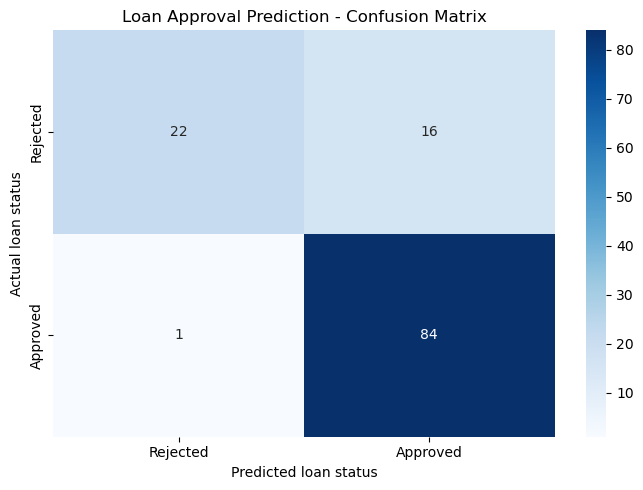

In [21]:
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Rejected", "Approved"],
    yticklabels=["Rejected", "Approved"]
)
plt.xlabel("Predicted loan status")
plt.ylabel("Actual loan status")
plt.title("Loan Approval Prediction - Confusion Matrix")
plt.tight_layout()
plt.show()


## Step 12: Plot the ROC curve

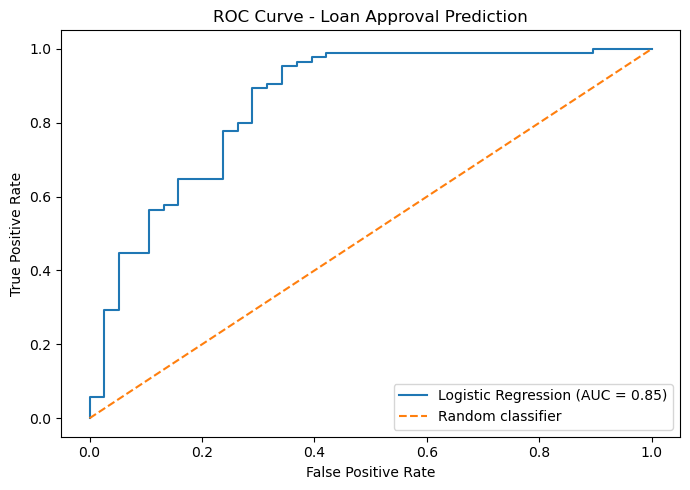

ROC-AUC score: 0.8523


In [23]:
fpr, tpr, thresholds = roc_curve(y_test, y_probability)
auc_score = roc_auc_score(y_test, y_probability)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {auc_score:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Loan Approval Prediction")
plt.legend()
plt.tight_layout()
plt.show()

print(f"ROC-AUC score: {auc_score:.4f}")


## Step 13: Save the trained pipeline

In [25]:
joblib.dump(model, "loan_approval_model.pkl")
print("Saved complete model pipeline as loan_approval_model.pkl")


Saved complete model pipeline as loan_approval_model.pkl


## Step 14: Load the new applicants dataset

Reads `new_loan_data.csv` if it exists; otherwise scores one built-in example applicant.

In [ ]:
import os

NEW_DATA_FILE = "new_loan_data.csv"

if os.path.exists(NEW_DATA_FILE):
    new_df = pd.read_csv(NEW_DATA_FILE)
    print(f"Loaded {len(new_df)} new applicants from {NEW_DATA_FILE}")
else:
    # Fall back to one example unseen loan application
    new_data = {
        'Gender': 'Male',
        'Married': 'Yes',
        'Dependents': '0',
        'Education': 'Graduate',
        'Self_Employed': 'No',
        'ApplicantIncome': 5000,
        'CoapplicantIncome': 2000,
        'LoanAmount': 150,
        'Loan_Amount_Term': 360,
        'Credit_History': 1,
        'Property_Area': 'Urban'
    }
    new_df = pd.DataFrame([new_data])
    print(f"{NEW_DATA_FILE} not found - using one example applicant instead.")

print("New dataset preview:")
display(new_df.head())


## Step 15: Prepare the new dataset

In [ ]:
# Keep the applicant ID for the output, but do not use it as a model feature
applicant_ids = new_df["Loan_ID"].copy() if "Loan_ID" in new_df.columns else None

new_X = new_df.drop(
    columns=["Loan_ID", "Loan_Status"],
    errors="ignore"
).copy()

new_X.columns = new_X.columns.str.strip()
new_X = new_X.replace(r"^\s*$", np.nan, regex=True)
new_X = new_X.replace([np.inf, -np.inf], np.nan)

# Match the text format used in training (e.g. Dependents "0", "1", "3+").
# A CSV can load Dependents as numbers (0, 1, 2), which would not match the
# text categories the encoder learned, so convert categorical values to text.
for col in categorical_cols:
    if col in new_X.columns:
        as_text = new_X[col].astype(str).str.strip().str.replace(r"\.0$", "", regex=True)
        new_X[col] = as_text.where(new_X[col].notna(), np.nan)

# Match the training feature names and order.
# Missing expected columns become NaN and are handled by the imputers.
# Extra columns are ignored.
new_X = new_X.reindex(columns=X.columns)

print("New input data prepared:")
display(new_X.head())


## Step 16: Predict loan outcomes for new applicants

In [41]:
new_predictions = model.predict(new_X)
new_probabilities = model.predict_proba(new_X)[:, 1]

print("Loan prediction results:")
display(new_predictions)


Loan prediction results:


array([1])

## Step 17: Export predictions to Excel

In [ ]:
# Build the results table (this was missing before, so the export failed)
results = new_X.copy()
if applicant_ids is not None:
    results.insert(0, "Loan_ID", applicant_ids.values)
results["Predicted_Loan_Status"] = np.where(new_predictions == 1, "Y", "N")
results["Approval_Probability"] = np.round(new_probabilities, 4)

output_file = "loan_prediction_results.xlsx"

results.to_excel(output_file, index=False)

print(f"Prediction results exported successfully to {output_file}")
display(results.head())


# Part 2: Model Improvements

The steps above keep the original baseline model unchanged. The steps below test ways to improve it: cross-validation, handling the weak recall on rejected loans, comparing other models, and inspecting the coefficients.

The baseline is much better at spotting approved loans than rejected ones, so these steps report **recall for the Rejected class** alongside accuracy and ROC-AUC.

## Step 18: Cross-validate the baseline model

A single train/test split of 123 test rows is a noisy estimate. Stratified 5-fold cross-validation on the full dataset gives a steadier picture.

In [ ]:
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import make_scorer, recall_score

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "accuracy": "accuracy",
    "roc_auc": "roc_auc",
    "recall_rejected": make_scorer(recall_score, pos_label=0),
    "f1_macro": "f1_macro",
}

def cv_summary(estimator, name):
    """Cross-validate an estimator and return mean and std for each metric."""
    scores = cross_validate(estimator, X, y, cv=cv, scoring=scoring)
    row = {"Model": name}
    for metric in scoring:
        values = scores[f"test_{metric}"]
        row[metric] = f"{values.mean():.3f} +/- {values.std():.3f}"
    return row

baseline_cv = cv_summary(model, "Logistic Regression (baseline)")
display(pd.DataFrame([baseline_cv]).set_index("Model"))

## Step 19: Improve recall on rejected loans

Two options: **class weights** (penalize mistakes on the rarer Rejected class more) and **threshold tuning** (require a higher approval probability before predicting Approved).

The threshold is chosen using out-of-fold predictions on the **training set only**, then applied once to the test set, so the test data is not used to tune it.

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import balanced_accuracy_score

# Option A: class weights
model_balanced = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced"))
])
model_balanced.fit(X_train, y_train)

y_pred_bal = model_balanced.predict(X_test)
print("Class-weighted model on the test set")
print(f"Accuracy: {accuracy_score(y_test, y_pred_bal) * 100:.2f}%")
print(classification_report(y_test, y_pred_bal,
                            target_names=["Rejected", "Approved"], zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_bal))

# Option B: tune the decision threshold of the baseline model
oof_prob = cross_val_predict(model, X_train, y_train, cv=cv,
                             method="predict_proba")[:, 1]

thresholds_grid = np.arange(0.30, 0.91, 0.01)
bal_acc = [balanced_accuracy_score(y_train, (oof_prob >= t).astype(int))
           for t in thresholds_grid]
best_threshold = float(thresholds_grid[int(np.argmax(bal_acc))])
print(f"\nBest threshold from training-set cross-validation: {best_threshold:.2f}")

y_pred_thr = (y_probability >= best_threshold).astype(int)
print("\nBaseline model with tuned threshold on the test set")
print(f"Accuracy: {accuracy_score(y_test, y_pred_thr) * 100:.2f}%")
print(classification_report(y_test, y_pred_thr,
                            target_names=["Rejected", "Approved"], zero_division=0))
print("Confusion matrix:")
print(confusion_matrix(y_test, y_pred_thr))

## Step 20: Compare other models

All models use the same preprocessing pipeline and the same cross-validation folds, so the comparison is fair. Sorted by ROC-AUC.

In [ ]:
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

def make_model(classifier):
    return Pipeline(steps=[("preprocessor", preprocessor), ("classifier", classifier)])

candidates = {
    "Logistic Regression (baseline)": model,
    "Logistic Regression (balanced)": model_balanced,
    "Random Forest": make_model(RandomForestClassifier(
        n_estimators=300, min_samples_leaf=3, random_state=42)),
    "Random Forest (balanced)": make_model(RandomForestClassifier(
        n_estimators=300, min_samples_leaf=3, class_weight="balanced", random_state=42)),
    "Gradient Boosting": make_model(GradientBoostingClassifier(random_state=42)),
}

comparison = pd.DataFrame([cv_summary(est, name) for name, est in candidates.items()])
comparison["_sort"] = comparison["roc_auc"].str.split(" ").str[0].astype(float)
comparison = comparison.sort_values("_sort", ascending=False).drop(columns="_sort")
display(comparison.set_index("Model"))

## Step 21: Inspect the model coefficients

For logistic regression, each coefficient shows how a feature moves the log-odds of approval. Positive values push toward Approved; negative values toward Rejected. Numeric features are standardized, so their coefficients are comparable. These show association in the data, not cause and effect.

In [ ]:
feature_names = model.named_steps["preprocessor"].get_feature_names_out()
coefficients = model.named_steps["classifier"].coef_[0]

coef_table = (
    pd.DataFrame({
        "Feature": feature_names,
        "Coefficient": coefficients,
        "Odds_Ratio": np.exp(coefficients),
    })
    .assign(Abs=lambda d: d["Coefficient"].abs())
    .sort_values("Abs", ascending=False)
    .drop(columns="Abs")
    .reset_index(drop=True)
)
display(coef_table.round(3))

top = coef_table.head(10).iloc[::-1]
plt.figure(figsize=(8, 5))
plt.barh(top["Feature"], top["Coefficient"],
         color=["tab:green" if v > 0 else "tab:red" for v in top["Coefficient"]])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Coefficient (log-odds of approval)")
plt.title("Top 10 Features by Absolute Coefficient")
plt.tight_layout()
plt.show()

## End of project

## Important notes

- Run the notebook from top to bottom.
- The training and new datasets must use consistent feature definitions and compatible data types.
- The pipeline learns imputation, encoding, and scaling from the training data only, then reuses those fitted steps for testing and new applicants.
- `Approval_Probability` is the model's estimated probability, not a guarantee of approval.
- This is an educational machine-learning example, not a validated lending decision system.
